In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader
import torch
import torch.nn as nn
from joblib import dump

# Configure base directory for both Google Colab and local environments
if "google.colab" in sys.modules:
    drive_path = Path("/content/drive/MyDrive/pytorch-projects/xor-function-neural-network")
    if not drive_path.exists():
        from google.colab import drive
        drive.mount("/content/drive")

    if drive_path.exists():
        base = str(drive_path)
    else:
        repo_name = "xor-function-neural-network"
        if not Path(repo_name).exists():
            !git clone https://github.com/nfor-ojong/xor-function-neural-network.git
        base = repo_name
else:
    cwd = Path.cwd()
    base = str(cwd.parent if cwd.name == "notebooks" else cwd)

os.makedirs(f"{base}/model", exist_ok=True)
os.makedirs(f"{base}/plots", exist_ok=True)

torch.manual_seed(42) # ensure reproducibility of results

train = pd.read_csv(base + "/data/train.csv") # load training data

Mounted at /content/drive


In [2]:
train.columns # view dataset columns

Index(['x1', 'x2', 'class'], dtype='object')

In [3]:
train.head() # first five samples in dataset

,x1,x2,class
0,-0.136282,3.244889,0
1,-5.305888,5.629232,0
2,-4.147647,-0.226319,1
3,-2.170794,3.946986,0
4,-5.555908,1.155239,0


In [4]:
train.info() # dataset information

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      320 non-null    float64
 1   x2      320 non-null    float64
 2   class   320 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 7.6 KB


In [5]:
train.describe() # descriptive statistics

,x1,x2,class
count,320.000000,320.000000,320.000000
mean,0.034098,0.093616,0.465625
std,3.614816,3.483030,0.499598
min,-5.940720,-5.944416,0.000000
25%,-3.128370,-2.808016,0.000000
50%,-0.135061,0.224914,0.000000
75%,3.174017,3.006768,1.000000
max,5.992965,5.996612,1.000000


In [6]:
train["class"].value_counts() # class distribution

,count
class,
0,171
1,149


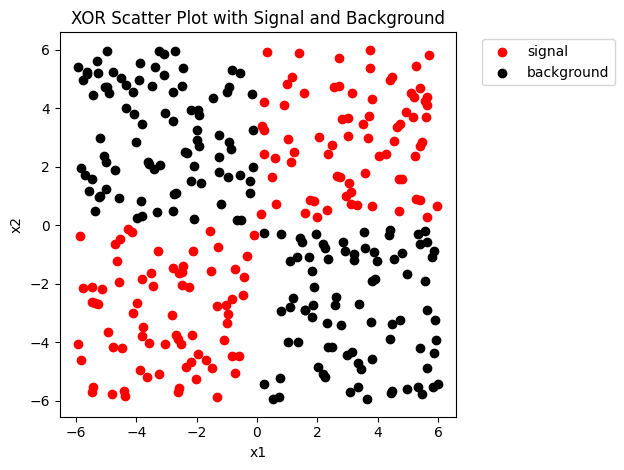

In [7]:
sig = train[train["class"] == 1] # signal
bkg = train[train["class"] == 0] # background

# Scatter plot of values when class = 1 (signal) and when class = 0 (background)
plt.scatter(sig["x1"], sig["x2"], color="red", label="signal")
plt.scatter(bkg["x1"], bkg["x2"], color="black", label="background")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("XOR Scatter Plot with Signal and Background")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left') # put legend outside the scatter plot
plt.tight_layout()
plt.savefig(base + "/plots/train_data_scatter_plot.png")
plt.show()

In [8]:
X = train.drop(columns=["class"]) # features
y = train["class"] # target
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y) # split and keep equal proportions of target in each split

scaler = StandardScaler() # scaler for feature standardization
X_train = scaler.fit_transform(X_train) # fit on training data
X_val = scaler.transform(X_val) # apply learned parameters from training data to validation data

# Convert data to tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train.to_numpy(), dtype=torch.float32).reshape(-1, 1)

X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val.to_numpy(), dtype=torch.float32).reshape(-1, 1) # convert to 2D tensor

# Verify data types
print("X_train_t dtype: ", X_train_t.dtype)
print("y_train_t dtype: ", y_train_t.dtype)
print("X_val_t dtype: ", X_val_t.dtype)
print("y_val_t dtype: ", y_val_t.dtype)

X_train_t dtype:  torch.float32
y_train_t dtype:  torch.float32
X_val_t dtype:  torch.float32
y_val_t dtype:  torch.float32


In [9]:
# Convert to TensorDataset
train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)

# Subdivide dataset into random batches for training and validation
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True) # training batches selected randomly
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False) # validation batches deterministic (shuffle=False)

# Build Neural Network
model = nn.Sequential(
    nn.Linear(X_train_t.shape[1], 4),
    nn.ReLU(),
    nn.Linear(4, 4),
    nn.ReLU(),
    nn.Linear(4, 1)
)
# Define loss function
criterion = nn.BCEWithLogitsLoss() # Can set pos_weight = ? if class imbalance slightly affects performance
# Define optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=0.003) # Experiment with learning rate

epochs = 2000 # total number of iterations

train_losses = [] # store train losses
val_losses = [] # store validation losses
epoch_values = []
# Training process
for epoch in range(1, epochs+1):
  epoch_loss_train = 0.0
  epoch_loss_val = 0.0

  model.train() # put model in training mode
  for X_batch_train, y_batch_train in train_loader:
    optimizer.zero_grad() # initialize gradients to 0
    pred_train = model(X_batch_train) # get training predictions be feeding train samples forward into the network
    train_loss = criterion(pred_train, y_batch_train) # compute the loss function

    train_loss.backward() # compute the derivatives of the train loss wrt model parameters (weights and biases)
    optimizer.step() # update model parameters using computed gradients

    epoch_loss_train += train_loss.item()

  # Evaluation phase
  model.eval() # put model in evaluation in mode
  with torch.no_grad(): # disable gradient calculations in this block
    for X_batch_val, y_batch_val in val_loader:
      preds_val = model(X_batch_val) # get validation models
      val_loss = criterion(preds_val, y_batch_val)
      epoch_loss_val += val_loss.item() # accumulate epoch loss across all batches

  if epoch%5 == 0:
    avg_train_loss = epoch_loss_train / len(train_loader)
    avg_val_loss = epoch_loss_val / len(val_loader)

    print(f"Epoch {epoch} train loss: {avg_train_loss} \t | Epoch {epoch} val loss: {avg_val_loss}")
    epoch_values.append(epoch)
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)

Epoch 5 train loss: 0.6684174090623856 	 | Epoch 5 val loss: 0.6543537676334381
Epoch 10 train loss: 0.6380617767572403 	 | Epoch 10 val loss: 0.6110233664512634
Epoch 15 train loss: 0.5888195261359215 	 | Epoch 15 val loss: 0.5439294874668121
Epoch 20 train loss: 0.5179266482591629 	 | Epoch 20 val loss: 0.45451076328754425
Epoch 25 train loss: 0.44120440632104874 	 | Epoch 25 val loss: 0.36922626197338104
Epoch 30 train loss: 0.3739682212471962 	 | Epoch 30 val loss: 0.29927124083042145
Epoch 35 train loss: 0.3179833050817251 	 | Epoch 35 val loss: 0.24286630004644394
Epoch 40 train loss: 0.2728479951620102 	 | Epoch 40 val loss: 0.19714491069316864
Epoch 45 train loss: 0.23787040449678898 	 | Epoch 45 val loss: 0.1631963849067688
Epoch 50 train loss: 0.21080402098596096 	 | Epoch 50 val loss: 0.13957254588603973
Epoch 55 train loss: 0.1898605413734913 	 | Epoch 55 val loss: 0.12186805531382561
Epoch 60 train loss: 0.17255584709346294 	 | Epoch 60 val loss: 0.10969958826899529
Epoch 

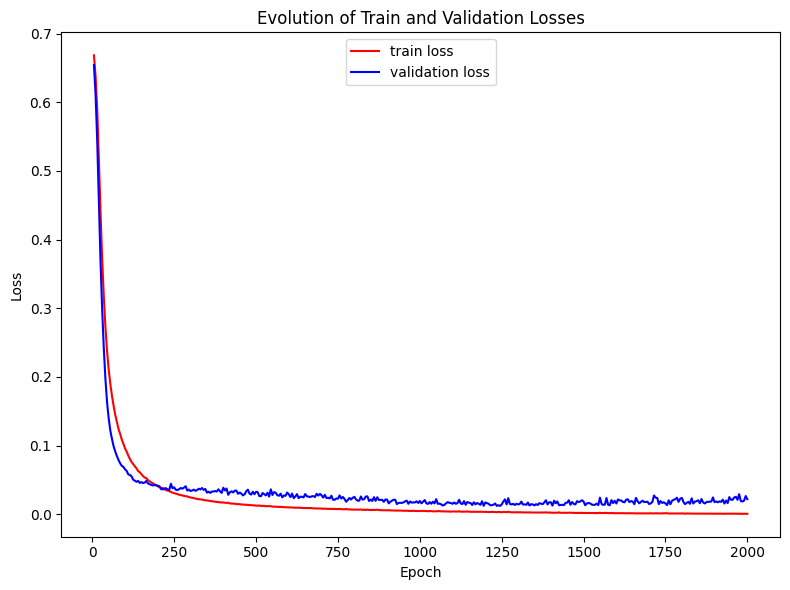

In [10]:
# Evolution of train loss with epoch
plt.figure(figsize=(8, 6))
plt.plot(epoch_values, train_losses, color="red", label="train loss")
plt.plot(epoch_values, val_losses, color="blue", label="validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Evolution of Train and Validation Losses")
plt.legend(loc="upper center")
plt.tight_layout()
plt.savefig(base + "/plots/train_validation_loss_evolution.png")
plt.show()

In [11]:
# Save model parameters only
torch.save(model.state_dict(), base + "/model/neural_network.pth")

# Save scaler
dump(scaler, base + "/model/standard_scaler.joblib")

['/content/drive/MyDrive/pytorch-projects/xor-function-neural-network/model/standard_scaler.joblib']

In [12]:
## Rename the variables in the loop and move to testing the model.